# Reto: Transformer autorregresivo como distribución variacional del modelo de Ising

**Curso:** Computación Científica Avanzada — Profesor Hernán Salinas
**Referencias:** Wu, Wang y Zhang, *Solving statistical mechanics using variational autoregressive networks*, PRL 122, 080602 (2019); Białas et al., *Sampling two-dimensional spin systems with transformers*, arXiv:2604.27738 (2026).

## Idea

Para un sistema con energía $E(\mathbf s)$ a temperatura $T$ (con $k_B = 1$), la distribución de equilibrio es la de Boltzmann, $p_B(\mathbf s) = e^{-E(\mathbf s)/T}/Z$. En lugar de muestrearla con Monte Carlo, entrenamos un modelo $q_\theta(\mathbf s)$ que la aproxime. El **principio variacional de Gibbs** dice que

$$F[q] = \langle E\rangle_q - T\,S[q] \;\ge\; F_B = -T\ln Z,$$

con igualdad solo si $q = p_B$, y además $D_{KL}(q\,\|\,p_B) = (F[q]-F_B)/T$. Por tanto, **minimizar la energía libre variacional $F[q_\theta]$ es lo mismo que acercar $q_\theta$ a $p_B$**, y no hace falta conocer $Z$.

El modelo es un **Transformer autorregresivo**: recorre los $N = L^2$ espines por filas y factoriza

$$q_\theta(\mathbf s) = \prod_{i=1}^{N} q_\theta(s_i \mid s_{<i}).$$

Eso permite (a) generar configuraciones exactas e independientes muestreando espín por espín, y (b) evaluar $\ln q_\theta(\mathbf s)$ en una sola pasada con máscara causal. El gradiente de $F$ se estima con el truco de la función de puntuación (REINFORCE):

$$\nabla_\theta F = \big\langle [E(\mathbf s) + T\ln q_\theta(\mathbf s)]\,\nabla_\theta \ln q_\theta(\mathbf s)\big\rangle_{q_\theta}
\quad\Longrightarrow\quad
\mathcal L_{aux} = \frac1M\sum_m \operatorname{stopgrad}(f_m)\,\ell_m,\qquad f_m = E_m + T\ell_m .$$

## Plan del notebook

1. Modelo de Ising: energía con frontera periódica y enumeración exacta para $L=4$.
2. El Transformer autorregresivo: muestreo y $\ln q_\theta$.
3. Entrenamiento variacional (pasos 2–7 del enunciado).
4. Validación en $L=4$ contra la enumeración exacta: $F$, $U$, $S$, $\langle|m|\rangle$, normalización de $q_\theta$ y $D_{KL}$.
5. Barrido en temperatura.
6. Red más grande ($L = 8$) comparada con Metropolis.
7. Conclusiones.

In [1]:
import math, time, itertools
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F_
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
torch.set_num_threads(max(1, torch.get_num_threads()))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams["figure.figsize"] = (10, 4); plt.rcParams["axes.grid"] = True
print("PyTorch", torch.__version__, "| dispositivo:", device)

PyTorch 2.14.1+cu130 | dispositivo: cpu


## 1. Modelo de Ising y enumeración exacta

Red cuadrada $L\times L$ con frontera periódica, $J = 1$, $h = 0$:

$$E(\mathbf s) = -J\sum_{x,y} s_{x,y}\,(s_{x+1,y} + s_{x,y+1}) - h\sum_{x,y} s_{x,y},$$

con índices módulo $L$ (cada par de vecinos se cuenta una sola vez).

In [2]:
def energia_ising(s, J=1.0, h=0.0):
    """Energía de un lote de configuraciones s de forma (M, L, L) con valores ±1 (tensor o arreglo)."""
    if isinstance(s, np.ndarray):
        s = torch.as_tensor(s)
    s = s.float()
    vecinos = torch.roll(s, -1, dims=1) + torch.roll(s, -1, dims=2)
    return -J * (s * vecinos).sum(dim=(1, 2)) - h * s.sum(dim=(1, 2))

def enumerar_exacto(L, T, J=1.0, h=0.0):
    """Enumera las 2^(L^2) configuraciones: devuelve F_B, U, S, <|m|> y el diccionario de p_B."""
    N = L * L
    idx = torch.arange(2 ** N)
    bits = ((idx[:, None] >> torch.arange(N)) & 1)            # (2^N, N) en {0,1}
    confs = (2 * bits - 1).view(-1, L, L)                        # en {-1, +1}
    E = energia_ising(confs, J, h)
    logw = -E / T
    logZ = torch.logsumexp(logw, 0)
    p = torch.exp(logw - logZ)
    F_B = -T * logZ
    U = (p * E).sum()
    S = -(p * torch.log(p)).sum()
    m_abs = (p * confs.float().mean(dim=(1, 2)).abs()).sum()
    return dict(F=F_B.item(), U=U.item(), S=S.item(), m_abs=m_abs.item(),
                confs=confs, E=E, p=p, logZ=logZ.item())

L_val = 4
for T in [1.5, 2.269, 3.5]:
    ex = enumerar_exacto(L_val, T)
    print(f"L = {L_val}, T = {T:5.3f}:  F/N = {ex['F']/L_val**2:+.4f}   U/N = {ex['U']/L_val**2:+.4f}   "
          f"S/N = {ex['S']/L_val**2:.4f}   <|m|> = {ex['m_abs']:.4f}")

L = 4, T = 1.500:  F/N = -2.0735   U/N = -1.9506   S/N = 0.0819   <|m|> = 0.9862
L = 4, T = 2.269:  F/N = -2.2013   U/N = -1.5658   S/N = 0.2801   <|m|> = 0.8439
L = 4, T = 3.500:  F/N = -2.7563   U/N = -0.7762   S/N = 0.5658   <|m|> = 0.4884


## 2. El Transformer autorregresivo

- **Tokens:** `0` = BOS (inicio), `1` = espín $-1$, `2` = espín $+1$.
- **Entrada desplazada:** $(\text{BOS}, s_1, \dots, s_{N-1})$; la salida en la posición $i$ predice $s_i$ y, gracias a la **máscara causal**, solo depende de $s_{<i}$.
- **Salida:** dos logits por posición → `log_softmax` → $\ln q_\theta(s_i = a \mid s_{<i})$.
- Sin *dropout*, para que muestreo y evaluación usen exactamente la misma distribución.

Además, imponemos la simetría $\mathbb Z_2$ del modelo de Ising con $h=0$ ($q_\theta(\mathbf s) = q_\theta(-\mathbf s)$): el primer espín se muestrea con probabilidad fija $1/2$ y el resto se predice relativo a él. Esto es opcional (se activa con `simetria_z2=True`) y evita que el modelo tenga que aprender la simetría por su cuenta; al medir $\langle |m|\rangle$ no cambia nada.

In [3]:
class TransformerIsing(nn.Module):
    def __init__(self, L, d_model=32, n_heads=4, n_layers=2, d_ff=64, simetria_z2=True):
        super().__init__()
        self.L, self.N = L, L * L
        self.simetria_z2 = simetria_z2
        self.emb_tok = nn.Embedding(3, d_model)                 # BOS, -1, +1
        self.emb_pos = nn.Embedding(self.N, d_model)
        capa = nn.TransformerEncoderLayer(d_model, n_heads, d_ff, dropout=0.0,
                                          batch_first=True, norm_first=True, activation="gelu")
        self.bloques = nn.TransformerEncoder(capa, n_layers, enable_nested_tensor=False)
        self.norma = nn.LayerNorm(d_model)
        self.salida = nn.Linear(d_model, 2)                     # logits de (-1, +1)
        mascara = torch.triu(torch.ones(self.N, self.N, dtype=torch.bool), diagonal=1)
        self.register_buffer("mascara", mascara)                # True = no se puede mirar

    def logits(self, tokens):
        """tokens: (M, N) entrada desplazada (BOS, s_1, ..., s_{N-1}) → logits (M, N, 2)."""
        n = tokens.shape[1]                                     # puede ser < N durante el muestreo
        pos = torch.arange(n, device=tokens.device)
        hdn = self.emb_tok(tokens) + self.emb_pos(pos)[None]
        hdn = self.bloques(hdn, mask=self.mascara[:n, :n], is_causal=True)
        return self.salida(self.norma(hdn))

    def log_prob(self, s):
        """ln q_θ(s) para un lote s de forma (M, L, L) con valores ±1. Con grafo de diferenciación."""
        M = s.shape[0]
        s_flat = s.view(M, self.N).long()
        if self.simetria_z2:                                    # trabajar relativo al primer espín
            s_rel = s_flat * s_flat[:, :1]
        else:
            s_rel = s_flat
        tok = (s_rel + 3) // 2                                  # -1 → 1, +1 → 2
        entrada = torch.cat([torch.zeros(M, 1, dtype=torch.long, device=s.device), tok[:, :-1]], dim=1)
        logp = F_.log_softmax(self.logits(entrada), dim=-1)   # (M, N, 2)
        objetivo = (tok - 1)                                    # índice 0 ↔ -1, 1 ↔ +1
        lp = logp.gather(-1, objetivo[..., None]).squeeze(-1)   # (M, N)
        if self.simetria_z2:
            lp = lp[:, 1:].sum(1) + math.log(0.5)               # el primer espín vale 1/2 exacto
        else:
            lp = lp.sum(1)
        return lp

    @torch.no_grad()
    def muestrear(self, M):
        """Genera M configuraciones independientes de q_θ, espín por espín. Sin grafo."""
        dev = self.mascara.device
        tok = torch.zeros(M, self.N, dtype=torch.long, device=dev)      # se llenará con 1/2
        entrada = torch.zeros(M, self.N, dtype=torch.long, device=dev)  # empieza en BOS
        for i in range(self.N):
            if self.simetria_z2 and i == 0:
                a = torch.ones(M, dtype=torch.long, device=dev)         # espín relativo s_1 = +1 (igual que en log_prob)
            else:
                lg = self.logits(entrada[:, : i + 1])[:, -1]           # logits de la posición i
                a = torch.multinomial(torch.softmax(lg, dim=-1), 1).squeeze(1)   # 0 ↔ -1, 1 ↔ +1
            tok[:, i] = a + 1
            if i + 1 < self.N:
                entrada[:, i + 1] = tok[:, i]
        s = (2 * (tok - 1) - 1)                                          # en {-1, +1}
        if self.simetria_z2:
            signo = torch.where(torch.rand(M, device=dev) < 0.5, -1, 1)
            s = s * signo[:, None]                                       # signo global ±1 con prob 1/2
        return s.view(M, self.L, self.L)

modelo = TransformerIsing(L_val).to(device)
print("Parámetros:", sum(p.numel() for p in modelo.parameters()))
s_prueba = modelo.muestrear(5)
print("Forma de las muestras:", tuple(s_prueba.shape), "| valores:", torch.unique(s_prueba).tolist())
print("ln q de las muestras:", modelo.log_prob(s_prueba).detach().cpu().numpy().round(3))

Parámetros: 17826
Forma de las muestras: (5, 4, 4) | valores: [-1, 1]
ln q de las muestras: [ -9.4    -8.692  -9.187 -10.155 -12.517]


### Verificación de la normalización, $\sum_{\mathbf s} q_\theta(\mathbf s) = 1$

Para $L=4$ podemos enumerar las $2^{16} = 65\,536$ configuraciones y sumar $q_\theta$. Esto comprueba que la factorización autorregresiva y la máscara causal están bien implementadas (antes de entrenar, con pesos aleatorios).

In [4]:
@torch.no_grad()
def q_total(modelo, confs, lote=4096):
    """Suma de q_θ sobre todas las configuraciones y vector de ln q_θ (en el mismo orden)."""
    lps = []
    for k in range(0, len(confs), lote):
        lps.append(modelo.log_prob(confs[k:k + lote].to(device)).cpu())
    lq = torch.cat(lps)
    return torch.exp(lq).sum().item(), lq

ex = enumerar_exacto(L_val, 2.269)
suma_q, _ = q_total(modelo, ex["confs"])
print(f"Σ q_θ(s) sobre las 2^16 configuraciones (modelo sin entrenar) = {suma_q:.6f}")

Σ q_θ(s) sobre las 2^16 configuraciones (modelo sin entrenar) = 1.000000


## 3. Entrenamiento variacional

En cada iteración (pasos 3–7 del enunciado):

1. Muestrear $M$ configuraciones $\mathbf s^{(m)} \sim q_\theta$ **sin** grafo de diferenciación.
2. Calcular $E_m$ con el Hamiltoniano y $\ell_m = \ln q_\theta(\mathbf s^{(m)})$ **con** grafo.
3. $f_m = E_m + T\ell_m$; estimadores $\hat F = \overline{f}$, $\hat U = \overline{E}$, $\hat S = -\overline{\ell}$.
4. $\mathcal L_{aux} = \frac1M\sum_m \operatorname{stopgrad}(f_m - b)\,\ell_m$ y un paso de Adam.

Sobre la **línea base $b$**: como $\langle \nabla_\theta \ln q_\theta\rangle_{q_\theta} = \nabla_\theta \sum_s q_\theta = 0$, restar cualquier constante $b$ a $f_m$ no cambia el gradiente esperado pero reduce mucho su varianza. Usamos $b = \overline{f}$ (media del lote), como en Wu et al. Con `linea_base=False` se recupera exactamente el estimador del enunciado.

In [5]:
def entrenar(modelo, T, K=1500, M=256, lr=2e-3, linea_base=True, J=1.0, h=0.0, cada=100, verbose=True, T_inicio=None):
    """Minimiza la energía libre variacional. Devuelve la historia de (F, U, S, <|m|>) por espín.
    Si se da T_inicio, la temperatura baja linealmente de T_inicio a T durante el primer 40 % de las
    iteraciones (recocido) y luego se mantiene en T."""
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, K, eta_min=lr / 10)
    N = modelo.N
    hist = {"F": [], "U": [], "S": [], "m": [], "std_f": []}
    t0 = time.time()
    for k in range(1, K + 1):
        T_k = T if T_inicio is None else T_inicio + (T - T_inicio) * min(1.0, k / (0.4 * K))
        modelo.eval()
        s = modelo.muestrear(M)                                  # paso 3 (sin grafo)
        modelo.train()
        E = energia_ising(s, J, h)                               # paso 4: energía
        ell = modelo.log_prob(s)                                 # paso 4: ln q_θ (con grafo)
        f = E + T_k * ell                                        # paso 5
        b = f.mean() if linea_base else 0.0
        L_aux = ((f - b).detach() * ell).mean()                  # paso 6: stopgrad(f) · ln q
        opt.zero_grad(); L_aux.backward()                        # paso 7
        nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
        opt.step(); sched.step()
        with torch.no_grad():
            hist["F"].append(f.mean().item() / N); hist["U"].append(E.mean().item() / N)
            hist["S"].append(-ell.mean().item() / N)
            hist["m"].append(s.float().mean(dim=(1, 2)).abs().mean().item())
            hist["std_f"].append(f.std().item() / N)
        if verbose and (k % cada == 0 or k == 1):
            print(f"it {k:5d} | F/N = {hist['F'][-1]:+.4f}  U/N = {hist['U'][-1]:+.4f}  "
                  f"S/N = {hist['S'][-1]:.4f}  <|m|> = {hist['m'][-1]:.3f}  | {time.time()-t0:.0f} s")
    return {k_: np.array(v) for k_, v in hist.items()}

@torch.no_grad()
def evaluar(modelo, T, M=4096, J=1.0, h=0.0):
    """Paso 8: lote independiente de evaluación → F/N, U/N, S/N, <|m|> con su error estándar."""
    modelo.eval()
    s = modelo.muestrear(M)
    E = energia_ising(s, J, h); ell = modelo.log_prob(s); f = E + T * ell
    N = modelo.N
    res = {}
    for nombre, v in [("F", f / N), ("U", E / N), ("S", -ell / N), ("m_abs", s.float().mean(dim=(1, 2)).abs())]:
        res[nombre] = (v.mean().item(), v.std().item() / math.sqrt(M))
    return res, s

## 4. Validación en $L = 4$ contra la enumeración exacta

Entrenamos a $T = 2.269$ (la temperatura crítica del sistema infinito, donde más fluctúa el sistema) y comparamos con los valores exactos.

In [6]:
T_val = 2.269
exacto = enumerar_exacto(L_val, T_val)
torch.manual_seed(1)
modelo = TransformerIsing(L_val).to(device)
hist = entrenar(modelo, T_val, K=1500, M=256)

it     1 | F/N = -1.3954  U/N = -0.0029  S/N = 0.6137  <|m|> = 0.174  | 0 s


it   100 | F/N = -2.1835  U/N = -1.6846  S/N = 0.2199  <|m|> = 0.910  | 5 s


it   200 | F/N = -2.1975  U/N = -1.5811  S/N = 0.2717  <|m|> = 0.855  | 9 s


it   300 | F/N = -2.2021  U/N = -1.5928  S/N = 0.2685  <|m|> = 0.856  | 15 s


it   400 | F/N = -2.2011  U/N = -1.5811  S/N = 0.2733  <|m|> = 0.848  | 20 s


it   500 | F/N = -2.2016  U/N = -1.5684  S/N = 0.2791  <|m|> = 0.843  | 25 s


... (6 outputs left out)

it  1200 | F/N = -2.2015  U/N = -1.6318  S/N = 0.2511  <|m|> = 0.878  | 58 s


it  1300 | F/N = -2.2011  U/N = -1.5684  S/N = 0.2788  <|m|> = 0.840  | 63 s


it  1400 | F/N = -2.2013  U/N = -1.5957  S/N = 0.2669  <|m|> = 0.862  | 68 s


it  1500 | F/N = -2.2015  U/N = -1.6104  S/N = 0.2605  <|m|> = 0.862  | 73 s


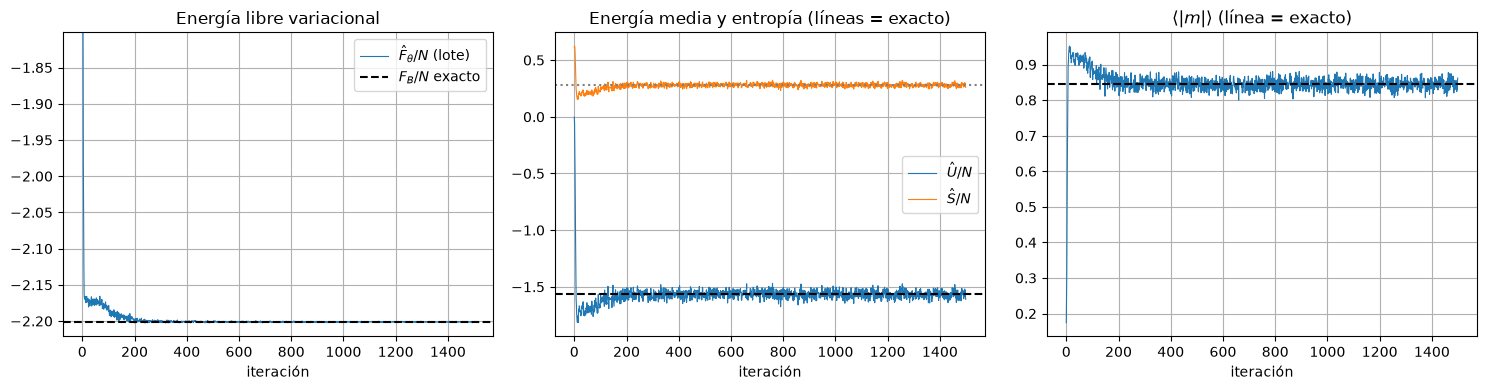

                       Transformer      exacto
F/N                -2.2011 ± 0.0001     -2.2013
U/N                -1.5583 ± 0.0079     -1.5658
S/N                +0.2833 ± 0.0035     +0.2801
<|m|>              +0.8410 ± 0.0035     +0.8439


In [7]:
N = L_val ** 2
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(hist["F"], lw=0.8, label=r"$\hat F_\theta/N$ (lote)")
ax[0].axhline(exacto["F"] / N, color="k", ls="--", label=r"$F_B/N$ exacto")
ax[0].set_ylim(exacto["F"] / N - 0.02, exacto["F"] / N + 0.4); ax[0].set_xlabel("iteración"); ax[0].legend()
ax[0].set_title("Energía libre variacional")
ax[1].plot(hist["U"], lw=0.8, label=r"$\hat U/N$"); ax[1].axhline(exacto["U"] / N, color="k", ls="--")
ax[1].plot(hist["S"], lw=0.8, label=r"$\hat S/N$"); ax[1].axhline(exacto["S"] / N, color="gray", ls=":")
ax[1].set_xlabel("iteración"); ax[1].legend(); ax[1].set_title("Energía media y entropía (líneas = exacto)")
ax[2].plot(hist["m"], lw=0.8); ax[2].axhline(exacto["m_abs"], color="k", ls="--")
ax[2].set_xlabel("iteración"); ax[2].set_title(r"$\langle|m|\rangle$ (línea = exacto)")
plt.tight_layout(); plt.show()

res, s_eval = evaluar(modelo, T_val)
print(f"{'':12s}{'Transformer':>22s}{'exacto':>12s}")
for k_, nombre in [("F", "F/N"), ("U", "U/N"), ("S", "S/N"), ("m_abs", "<|m|>")]:
    ex_v = exacto[k_] / N if k_ != "m_abs" else exacto[k_]
    print(f"{nombre:12s}{res[k_][0]:+14.4f} ± {res[k_][1]:.4f}{ex_v:+12.4f}")

### Normalización, $D_{KL}$ y cota variacional

Con las $2^{16}$ configuraciones enumeradas calculamos **exactamente** (sin muestreo):

- $\sum_{\mathbf s} q_\theta(\mathbf s)$, que debe ser 1;
- $F[q_\theta] = \sum_s q_\theta (E + T\ln q_\theta)$, que debe cumplir $F[q_\theta] \ge F_B$;
- $D_{KL}(q_\theta\|p_B) = \sum_s q_\theta \ln(q_\theta/p_B)$, que debe coincidir con $(F[q_\theta]-F_B)/T$.

In [8]:
suma_q, lq = q_total(modelo, exacto["confs"])
q = torch.exp(lq)
F_exacto_q = (q * (exacto["E"] + T_val * lq)).sum().item()
KL_directa = (q * (lq - torch.log(exacto["p"]))).sum().item()
KL_por_F = (F_exacto_q - exacto["F"]) / T_val
print(f"Σ q_θ                       = {suma_q:.6f}")
print(f"F[q_θ] exacto (enumeración) = {F_exacto_q:.4f}   F_B = {exacto['F']:.4f}   →  F[q_θ] - F_B = {F_exacto_q - exacto['F']:.4f} ≥ 0")
print(f"D_KL(q_θ || p_B) directa    = {KL_directa:.5f}")
print(f"(F[q_θ] - F_B)/T            = {KL_por_F:.5f}")
print(f"Estimación con lote de 4096 = {res['F'][0]*N:.4f} ± {res['F'][1]*N:.4f}  (puede quedar por debajo de F_B por fluctuación)")

# ¿Qué tan bien reproduce q_θ las probabilidades individuales?
orden = torch.argsort(exacto["p"], descending=True)[:2000]
plt.figure(figsize=(5, 4.5))
plt.loglog(exacto["p"][orden], q[orden], ".", ms=3, alpha=0.5)
lim = [exacto["p"][orden].min().item(), exacto["p"].max().item()]
plt.plot(lim, lim, "k--", lw=1); plt.xlabel(r"$p_B(\mathbf s)$ exacta"); plt.ylabel(r"$q_\theta(\mathbf s)$")
plt.title("2000 configuraciones más probables, T = 2.269"); plt.show()

Σ q_θ                       = 1.000000
F[q_θ] exacto (enumeración) = -35.2199   F_B = -35.2213   →  F[q_θ] - F_B = 0.0014 ≥ 0
D_KL(q_θ || p_B) directa    = 0.00062
(F[q_θ] - F_B)/T            = 0.00062
Estimación con lote de 4096 = -35.2175 ± 0.0013  (puede quedar por debajo de F_B por fluctuación)


<Figure size 500x450 with 1 Axes>

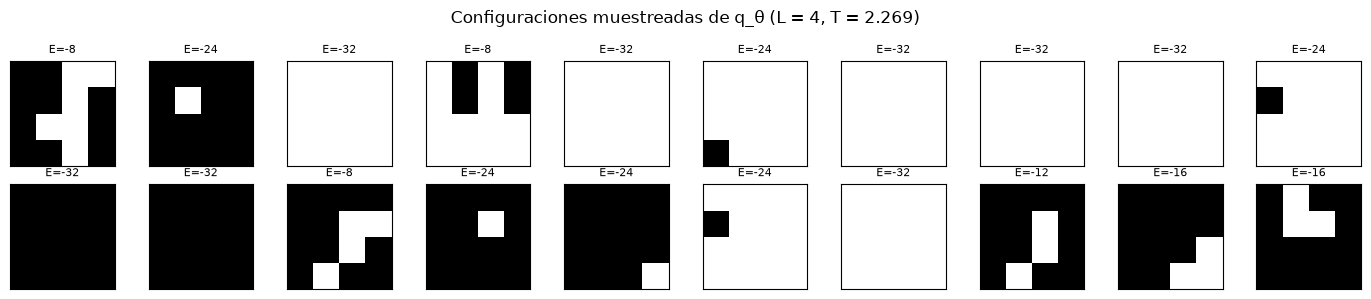

In [9]:
# Configuraciones generadas por el Transformer (L = 4, T = 2.269)
fig, axes = plt.subplots(2, 10, figsize=(14, 3))
for a_, s_ in zip(axes.flat, s_eval[:20].cpu()):
    a_.imshow(s_, cmap="gray", vmin=-1, vmax=1); a_.set_xticks([]); a_.set_yticks([])
    a_.set_title(f"E={energia_ising(s_[None])[0].item():+.0f}", fontsize=8)
plt.suptitle("Configuraciones muestreadas de q_θ (L = 4, T = 2.269)"); plt.tight_layout(); plt.show()

### ¿Y sin línea base?

Para comparar con el estimador tal como está en el enunciado ($\hat{\mathbf g} = \frac1M\sum f_m\nabla\ell_m$, sin restar nada), repetimos el entrenamiento con `linea_base=False`.

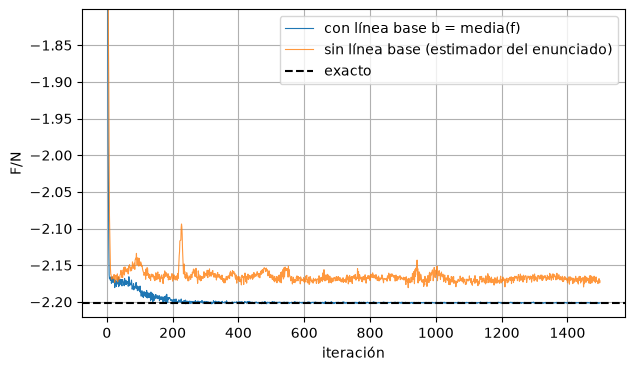

F/N final: con línea base -2.2011   sin línea base -2.1697   exacto -2.2013


In [10]:
torch.manual_seed(1)
modelo_sin = TransformerIsing(L_val).to(device)
hist_sin = entrenar(modelo_sin, T_val, K=1500, M=256, linea_base=False, verbose=False)
plt.figure(figsize=(7, 4))
plt.plot(hist["F"], lw=0.8, label="con línea base b = media(f)")
plt.plot(hist_sin["F"], lw=0.8, alpha=0.8, label="sin línea base (estimador del enunciado)")
plt.axhline(exacto["F"] / N, color="k", ls="--", label="exacto")
plt.ylim(exacto["F"] / N - 0.02, exacto["F"] / N + 0.4); plt.xlabel("iteración"); plt.ylabel("F/N"); plt.legend(); plt.show()
res_sin, _ = evaluar(modelo_sin, T_val)
print(f"F/N final: con línea base {res['F'][0]:+.4f}   sin línea base {res_sin['F'][0]:+.4f}   exacto {exacto['F']/N:+.4f}")

## 5. Barrido en temperatura ($L = 4$)

Comparamos $F/N$, $U/N$, $S/N$ y $\langle|m|\rangle$ con la enumeración exacta para varias temperaturas.

**Recocido (annealing).** A temperatura baja la energía libre tiene dos mínimos muy separados (todos los espines $+1$ o todos $-1$) y el entrenamiento desde pesos aleatorios puede quedar atrapado en una distribución intermedia (*mode collapse*). En una primera prueba, entrenando desde cero a $T = 1$, el modelo se estancó en $F/N = -1.55$ frente al exacto $-2.04$ ($D_{KL} \approx 8$). La solución estándar (Wu et al., 2019) es **recorrer las temperaturas de mayor a menor reutilizando los pesos**: la distribución a $T$ alta es fácil de aprender y sirve de punto de partida para la siguiente.

T = 4.000: F/N -3.0503 (exacto -3.0503)  <|m|> 0.418 (exacto 0.418)  D_KL = 0.0003


T = 3.000: F/N -2.4901 (exacto -2.4902)  <|m|> 0.608 (exacto 0.601)  D_KL = 0.0003


T = 2.600: F/N -2.3124 (exacto -2.3126)  <|m|> 0.724 (exacto 0.729)  D_KL = 0.0003


T = 2.269: F/N -2.2013 (exacto -2.2013)  <|m|> 0.849 (exacto 0.844)  D_KL = 0.0003


T = 2.000: F/N -2.1381 (exacto -2.1382)  <|m|> 0.923 (exacto 0.919)  D_KL = 0.0003


T = 1.500: F/N -2.0735 (exacto -2.0735)  <|m|> 0.985 (exacto 0.986)  D_KL = 0.0002


T = 1.000: F/N -2.0436 (exacto -2.0437)  <|m|> 0.999 (exacto 0.999)  D_KL = 0.0002


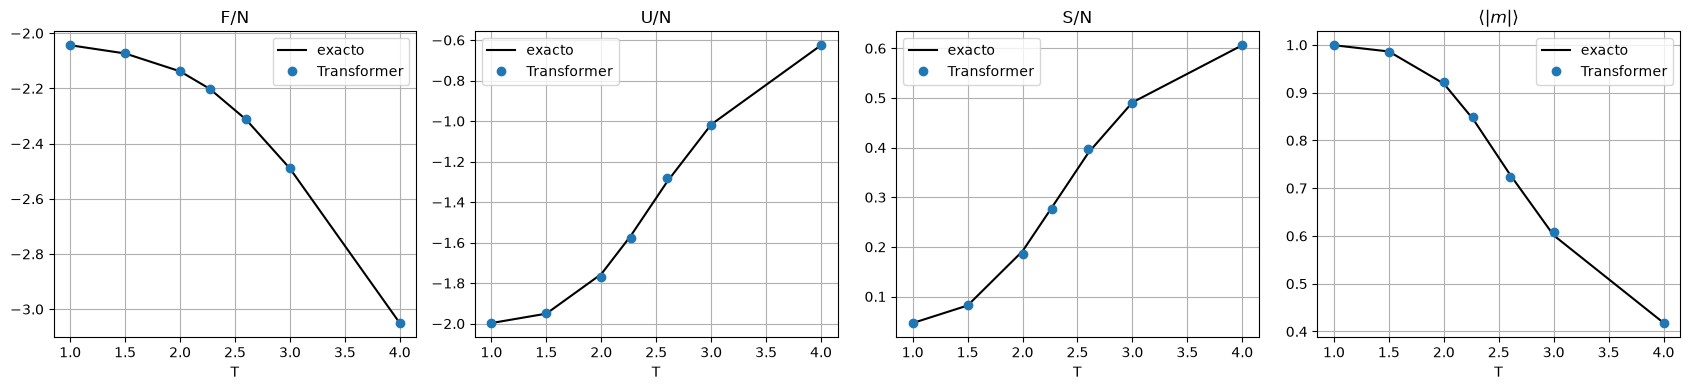

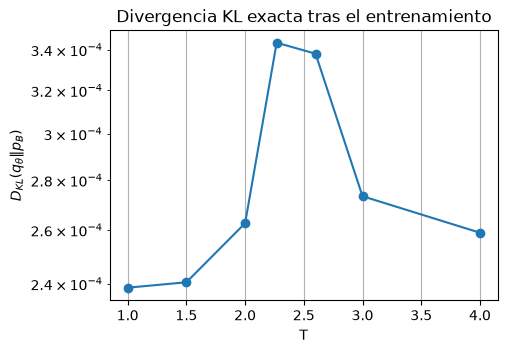

In [11]:
temps = [4.0, 3.0, 2.6, 2.269, 2.0, 1.5, 1.0]        # de mayor a menor: recocido
filas = []
torch.manual_seed(2)
m_T = TransformerIsing(L_val).to(device)              # un solo modelo que se va reutilizando
for T in temps:
    entrenar(m_T, T, K=800, M=256, verbose=False)
    r, _ = evaluar(m_T, T)
    ex = enumerar_exacto(L_val, T)
    _, lq_T = q_total(m_T, ex["confs"])
    KL = (torch.exp(lq_T) * (lq_T - torch.log(ex["p"]))).sum().item()
    filas.append((T, r["F"][0], ex["F"] / N, r["U"][0], ex["U"] / N, r["S"][0], ex["S"] / N, r["m_abs"][0], ex["m_abs"], KL))
    print(f"T = {T:5.3f}: F/N {r['F'][0]:+.4f} (exacto {ex['F']/N:+.4f})  <|m|> {r['m_abs'][0]:.3f} (exacto {ex['m_abs']:.3f})  D_KL = {KL:.4f}")

filas = np.array(filas)[np.argsort([f[0] for f in filas])]
fig, ax = plt.subplots(1, 4, figsize=(17, 4))
for j, (nombre, c1, c2) in enumerate([("F/N", 1, 2), ("U/N", 3, 4), ("S/N", 5, 6), (r"$\langle|m|\rangle$", 7, 8)]):
    ax[j].plot(filas[:, 0], filas[:, c2], "k-", label="exacto"); ax[j].plot(filas[:, 0], filas[:, c1], "o", label="Transformer")
    ax[j].set_xlabel("T"); ax[j].set_title(nombre); ax[j].legend()
plt.tight_layout(); plt.show()
plt.figure(figsize=(5, 3.5)); plt.semilogy(filas[:, 0], filas[:, 9], "o-"); plt.xlabel("T"); plt.ylabel(r"$D_{KL}(q_\theta\|p_B)$")
plt.title("Divergencia KL exacta tras el entrenamiento"); plt.show()

## 6. Red más grande: $L = 8$ comparada con Metropolis

Para $L = 8$ ($N = 64$, $2^{64}$ configuraciones) ya no hay enumeración exacta. Comparamos $U/N$ y $\langle|m|\rangle$ con una simulación Monte Carlo de Metropolis a $T = 2.5$ (por encima de $T_c$, donde el modelo aún fluctúa mucho). Entrenamos con **recocido** desde $T = 4$: en una prueba previa sin recocido, directamente a $T = 2.269$, el modelo se quedó en la fase ordenada ($\langle|m|\rangle \approx 0.89$ frente a $0.78$ de Metropolis). En CPU cada iteración cuesta 64 pasadas del Transformer para muestrear, así que usamos un modelo pequeño ($\approx 40$ mil parámetros) y 1000 iteraciones (unos 8 minutos).

In [12]:
def metropolis(L, T, n_real=64, n_term=3000, n_muestras=200, cada=10, seed=0):
    """Metropolis vectorizado por subredes (tablero de ajedrez), frontera periódica, L par."""
    rng = np.random.default_rng(seed)
    s = rng.choice([-1, 1], size=(n_real, L, L)).astype(np.int8)
    ii, jj = np.indices((L, L)); masks = [((ii + jj) % 2 == c) for c in (0, 1)]
    def barrido(s):
        for mk in masks:
            vec = np.roll(s, 1, 1) + np.roll(s, -1, 1) + np.roll(s, 1, 2) + np.roll(s, -1, 2)
            dE = 2 * s * vec
            acepta = (rng.random(s.shape) < np.exp(-dE / T)) & mk
            s = np.where(acepta, -s, s).astype(np.int8)
        return s
    for _ in range(n_term): s = barrido(s)
    out = []
    for _ in range(n_muestras):
        for _ in range(cada): s = barrido(s)
        out.append(s.copy())
    return np.concatenate(out)

L8, T8 = 8, 2.5
t0 = time.time()
mc = metropolis(L8, T8)
E_mc = energia_ising(mc).numpy() / L8**2; m_mc = np.abs(mc.mean(axis=(1, 2)))
print(f"Metropolis ({len(mc)} configuraciones, {time.time()-t0:.0f} s):  U/N = {E_mc.mean():+.4f} ± {E_mc.std()/np.sqrt(len(mc)):.4f}   "
      f"<|m|> = {m_mc.mean():.4f} ± {m_mc.std()/np.sqrt(len(mc)):.4f}")

torch.manual_seed(3)
modelo8 = TransformerIsing(L8, d_model=48, n_heads=4, n_layers=2, d_ff=96).to(device)
print("Parámetros:", sum(p.numel() for p in modelo8.parameters()))
hist8 = entrenar(modelo8, T8, K=1000, M=128, lr=2e-3, cada=100, T_inicio=4.0)
res8, s8 = evaluar(modelo8, T8, M=1024)
print(f"\nTransformer L=8:  F/N = {res8['F'][0]:+.4f}   U/N = {res8['U'][0]:+.4f} ± {res8['U'][1]:.4f}   "
      f"S/N = {res8['S'][0]:.4f}   <|m|> = {res8['m_abs'][0]:.4f} ± {res8['m_abs'][1]:.4f}")

Metropolis (12800 configuraciones, 1 s):  U/N = -1.2209 ± 0.0029   <|m|> = 0.6023 ± 0.0023
Parámetros: 41330


it     1 | F/N = -2.6384  U/N = -0.0308  S/N = 0.6525  <|m|> = 0.111  | 1 s


it   100 | F/N = -2.6599  U/N = -0.4741  S/N = 0.6030  <|m|> = 0.310  | 47 s


it   200 | F/N = -2.4914  U/N = -0.7593  S/N = 0.5330  <|m|> = 0.463  | 93 s


it   300 | F/N = -2.3457  U/N = -0.9233  S/N = 0.4947  <|m|> = 0.481  | 138 s


it   400 | F/N = -2.1944  U/N = -1.2495  S/N = 0.3780  <|m|> = 0.626  | 183 s


... (3 outputs left out)

it   800 | F/N = -2.2080  U/N = -1.2432  S/N = 0.3859  <|m|> = 0.632  | 369 s


it   900 | F/N = -2.2075  U/N = -1.1602  S/N = 0.4189  <|m|> = 0.558  | 414 s


it  1000 | F/N = -2.2093  U/N = -1.2827  S/N = 0.3706  <|m|> = 0.642  | 460 s



Transformer L=8:  F/N = -2.2077   U/N = -1.2134 ± 0.0102   S/N = 0.3977   <|m|> = 0.6031 ± 0.0081


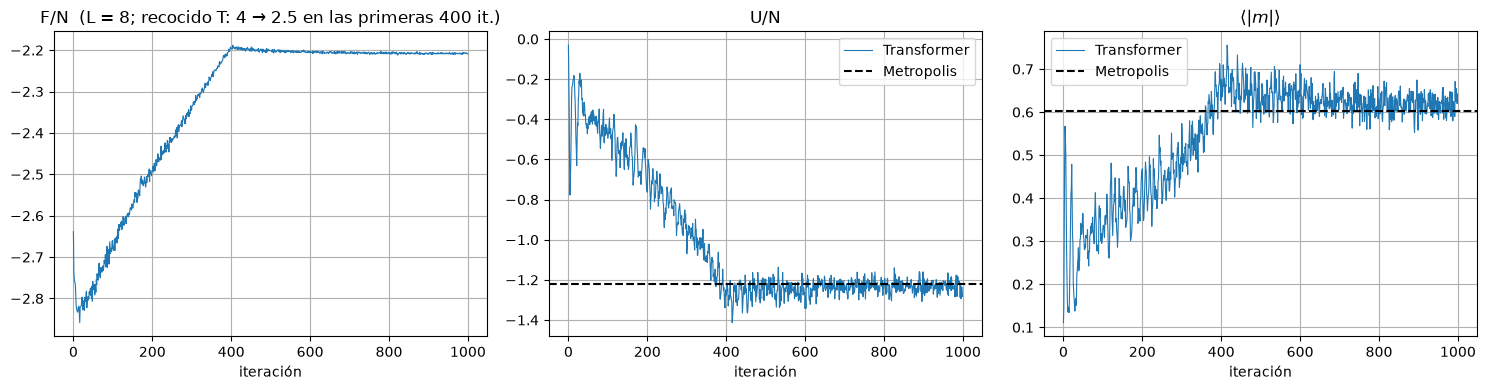

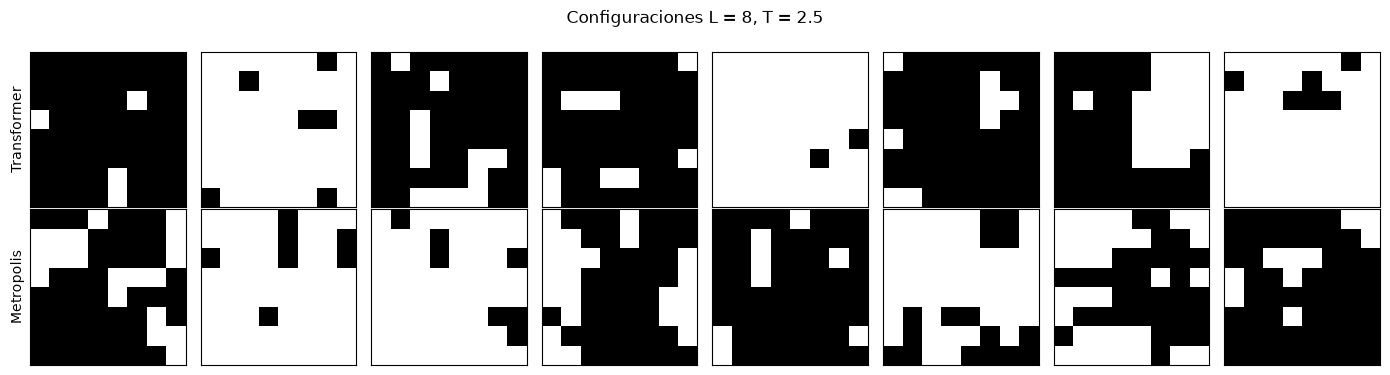

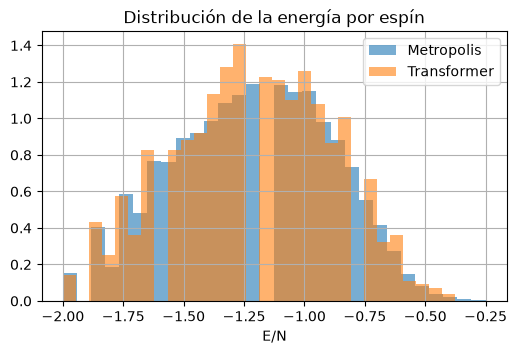

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(hist8["F"], lw=0.8); ax[0].set_xlabel("iteración"); ax[0].set_title("F/N  (L = 8; recocido T: 4 → 2.5 en las primeras 400 it.)")
ax[1].plot(hist8["U"], lw=0.8, label="Transformer"); ax[1].axhline(E_mc.mean(), color="k", ls="--", label="Metropolis")
ax[1].set_xlabel("iteración"); ax[1].set_title("U/N"); ax[1].legend()
ax[2].plot(hist8["m"], lw=0.8, label="Transformer"); ax[2].axhline(m_mc.mean(), color="k", ls="--", label="Metropolis")
ax[2].set_xlabel("iteración"); ax[2].set_title(r"$\langle|m|\rangle$"); ax[2].legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 8, figsize=(14, 3.8))
for a_, s_ in zip(axes[0], s8[:8].cpu()):
    a_.imshow(s_, cmap="gray", vmin=-1, vmax=1); a_.set_xticks([]); a_.set_yticks([])
for a_, s_ in zip(axes[1], mc[:8]):
    a_.imshow(s_, cmap="gray", vmin=-1, vmax=1); a_.set_xticks([]); a_.set_yticks([])
axes[0, 0].set_ylabel("Transformer"); axes[1, 0].set_ylabel("Metropolis")
plt.suptitle(f"Configuraciones L = 8, T = {T8}"); plt.tight_layout(); plt.show()

# Histograma de la energía por espín: ¿coinciden las distribuciones?
E8 = energia_ising(s8).cpu().numpy() / L8**2
plt.figure(figsize=(6, 3.5))
plt.hist(E_mc, bins=30, density=True, alpha=0.6, label="Metropolis"); plt.hist(E8, bins=30, density=True, alpha=0.6, label="Transformer")
plt.xlabel("E/N"); plt.legend(); plt.title("Distribución de la energía por espín"); plt.show()

## 7. Conclusiones

- **El principio variacional funciona como método de entrenamiento.** Sin conocer $Z$ ni usar datos, minimizar $\hat F_\theta = \overline{E + T\ln q_\theta}$ con el estimador de la función de puntuación lleva al Transformer a reproducir la distribución de Boltzmann. En $L=4$, $T=2.269$: $F/N = -2.2011$ frente a $-2.2013$ exacto; $U/N$, $S/N$ y $\langle|m|\rangle$ coinciden dentro del error estadístico, $\sum_s q_\theta = 1$ exactamente y $D_{KL} = 6\times10^{-4}$, igual a $(F[q_\theta]-F_B)/T$ calculado por enumeración.
- **La línea base importa.** Restar la media del lote a $f_m$ no cambia el gradiente esperado pero reduce su varianza: con ella el modelo converge en ~300 iteraciones; sin ella (estimador crudo del enunciado) queda en $F/N = -2.17$ tras 1500.
- **A baja temperatura hay que recocer.** Desde pesos aleatorios, a $T=1$ el entrenamiento se atasca ($D_{KL}\approx 8$). Bajando la temperatura por etapas y reutilizando los pesos, todo el barrido $T\in[1,4]$ queda con $D_{KL} \le 3\times10^{-4}$ y $F/N$ coincide con el exacto en cuatro cifras. Lo mismo ocurre en $L=8$ cerca de $T_c$: sin recocido el modelo colapsa a la fase ordenada; con recocido desde $T=4$ reproduce $U/N$ ($-1.213 \pm 0.010$ frente a $-1.221 \pm 0.003$) y $\langle|m|\rangle$ ($0.603 \pm 0.008$ frente a $0.602 \pm 0.002$) de Metropolis a $T=2.5$.
- **Ventajas y límites.** El Transformer genera configuraciones **independientes** (sin tiempo de autocorrelación, a diferencia de Metropolis) y da directamente $F$ y $S$, que Monte Carlo no mide de forma sencilla. A cambio, muestrear es secuencial ($N$ pasadas por configuración), el estimador del gradiente es ruidoso cerca de $T_c$, y con lotes finitos $\hat F$ puede caer por debajo de $F_B$ aunque la cota $F[q_\theta]\ge F_B$ sea exacta.